In [9]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.cluster import KMeans


In [25]:
iris= load_iris()
df=pd.DataFrame(iris.data,columns=iris.feature_names)
df.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2


In [11]:
df.shape

(150, 4)

In [26]:

df.info()
df.isnull().sum().sum()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 4 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   sepal length (cm)  150 non-null    float64
 1   sepal width (cm)   150 non-null    float64
 2   petal length (cm)  150 non-null    float64
 3   petal width (cm)   150 non-null    float64
dtypes: float64(4)
memory usage: 4.8 KB


np.int64(0)

In [27]:
# Apply K-Means clustering and generate cluster labels
km = KMeans(n_clusters=3, random_state=42, n_init=10)
labels = km.fit_predict(df)
df['cluster'] = labels

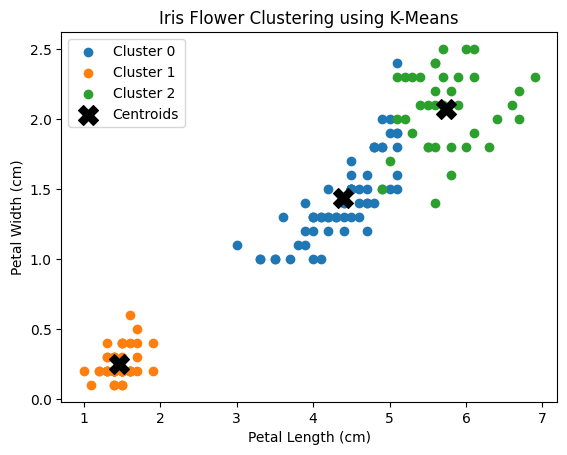

In [28]:
# Visualize the clusters
for c in range(3):
    sub = df[df['cluster'] == c]
    plt.scatter(
        sub['petal length (cm)'],
        sub['petal width (cm)'],
        label=f'Cluster {c}'
    )

plt.scatter(
    km.cluster_centers_[:, 2],
    km.cluster_centers_[:, 3],
    marker='X',
    s=200,
    color='black',
    label='Centroids'
)

plt.xlabel('Petal Length (cm)')
plt.ylabel('Petal Width (cm)')
plt.title('Iris Flower Clustering using K-Means')
plt.legend()
plt.show()

In [29]:
#analyze cluster centres
km.cluster_centers_.round(2)

array([[5.9 , 2.75, 4.39, 1.43],
       [5.01, 3.43, 1.46, 0.25],
       [6.85, 3.07, 5.74, 2.07]])

In [33]:
# Predict the cluster for a new flower

new_flower = pd.DataFrame(
    [[5.1, 3.5, 1.4, 0.2]],
    columns=iris.feature_names
)

cluster = km.predict(new_flower)[0]

print("New flower features:")
display(new_flower)

print("Predicted cluster:", cluster)

New flower features:


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.1,3.5,1.4,0.2


Predicted cluster: 1
